# Buckling of clamped-free annular plates compressed on the outer edge (Majumdar 1971)

Majumdar [1] studied, in theory and in tests on aluminium plates, the buckling of an annular plate
clamped on the outer edge, free on the inner edge and compressed by a uniform radial force on the
outer edge. Unlike the annulus compressed on both edges (Yamaki [2]), whose membrane state is
uniform, the free inner edge gives the non-uniform state of Lamé, and the mode changes from
axisymmetric to waves along the circumference as the hole grows. This notebook computes the
buckling loads with `annular_clpt_donnell` of panels, the pre-buckling state coming from a linear
static case, and compares them with the experiments of [1], Fig. 2.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jn_zeros

import panels
from panels.shell import Shell
from panels.multidomain import MultiDomain

%matplotlib inline
print('panels', panels.__version__)
T_START = time.time()


def print_table(rows, headers):
    cols = list(zip(*([headers] + [[str(c) for c in r] for r in rows])))
    widths = [max(len(c) for c in col) for col in cols]
    fmt = '  '.join('%%%ds' % w for w in widths)
    print(fmt % tuple(headers))
    print('  '.join('-'*w for w in widths))
    for r in rows:
        print(fmt % tuple(str(c) for c in r))


def rel(value, ref):
    # relative difference in per cent
    return 100.*(value - ref)/ref

panels 0.15.0


## 1. Specimens and load parameter

From [1]: plates of 2024 aluminium, 0.041 in thick, clamped between two steel rings of inner
diameter 8 in, so that the outer radius is $a = 4$ in; inner radii $b = 0, 0.5, 2, 2.5, 3$ in
([1], Table 1). The assembly was heated and the larger thermal expansion of the aluminium plate,
restrained by the steel rings, compressed its outer edge radially; the buckling temperatures were
found with Southwell plots and converted by [1] into the load parameter

$$k = \frac{N_{0,cr} a^2}{D}, \qquad D = \frac{E h^3}{12 (1 - \nu^2)}$$

$N_0$ being the radial compressive force per unit length at the outer edge ([1], nomenclature and
Eq. (8); the definition is confirmed by the relation of $k$ to the parameter $k'$ of the strip in
[1], p. 1704). $k$ does not depend on $E$; [1] does not give $\nu$, and the free inner edge makes
$k$ depend on it, so $\nu = 0.30$ and $0.33$ are both computed.

In [2]:
A_OUT = 4.               # in, [1] p. 1704: steel rings of inner diameter 8 in
H = 0.041                # in, [1] p. 1704
B_IN = (0.5, 2., 2.5, 3.)   # in, [1] Table 1 (b = 0 is the solid plate, Section 5)
E = 10.6e6               # psi, not given in [1]: k does not depend on it
NUS = (0.30, 0.33)       # not given in [1]


def flexural_rigidity(nu):
    return E*H**3/(12*(1 - nu**2))

## 2. Pre-buckling state and model

An annulus compressed by $N_0$ on the outer edge $\rho = a$ and free on the inner edge $\rho = b$
has the axisymmetric membrane state of Lamé ([1], Eq. (2))

$$N_{\rho\rho} = -\frac{N_0 a^2}{a^2 - b^2} \left(1 - \frac{b^2}{\rho^2}\right), \qquad
N_{\theta\theta} = -\frac{N_0 a^2}{a^2 - b^2} \left(1 + \frac{b^2}{\rho^2}\right), \qquad
N_{\rho\theta} = 0$$

The full annulus is made of two half annuli of `annular_clpt_donnell` whose radial edges are free
and connected with `'SSycte'`. The outer edge is clamped, $w = w_{,\rho} = 0$, has $v = 0$, which
removes the in-plane rigid motions without changing the axisymmetric state, and carries the radial
force $N_0$ per unit length (along $x = r - \rho$, which points inwards); the inner edge is free.
Each field is a Ritz series of Bardell's hierarchical functions, $m$ terms along the radius and $n$
along each half circumference [3]. The linear static case gives the geometric stiffness
$\boldsymbol{K}_G(\boldsymbol{c})$ and `MultiDomain.linear_buckling` the critical load factor;
with $N_0 = D/a^2$ the factor is $k$.

In [3]:
def annulus(b, N0, m, n, nu):
    halves = []
    for _ in range(2):
        s = Shell(model='annular_clpt_donnell', a=A_OUT - b, b=np.pi*A_OUT,
                  r=A_OUT, m=m, n=n, plyt=H, stack=[0], laminaprop=(E, nu))
        for e in ('y1', 'y2', 'x2'):
            for f in ('u', 'v', 'w', 'ur', 'vr', 'wr'):
                setattr(s, e + f, 1)
        s.x1u = 1                         # outer edge: radial force, u free
        s.x1v = 0                         # no in-plane rigid motion
        s.x1w = s.x1wr = 0                # clamped
        s.add_distr_load_fixed_x(0., funcx=lambda y: N0 + 0*y)
        halves.append(s)
    p1, p2 = halves
    conn = [dict(p1=p1, p2=p2, func='SSycte', ycte1=p1.b, ycte2=0),
            dict(p1=p1, p2=p2, func='SSycte', ycte1=0, ycte2=p2.b)]
    return MultiDomain([p1, p2], conn)


def buckling(b, m, n, nu):
    # k = N0 a^2/D of the least load factor, and the model and first mode
    md = annulus(b, flexural_rigidity(nu)/A_OUT**2, m, n, nu)
    eigvals, eigvecs = md.linear_buckling(num_eigvalues=6, silent=True)
    i = np.argmin(np.abs(eigvals))
    return eigvals[i], md, eigvecs[:, i]

The membrane state of the linear static case, $b = 2$ in, along a radius, against Lamé's solution
($N_{xx} = N_{\rho\rho}$, $N_{yy} = N_{\theta\theta}$):

In [4]:
N0 = 1.
b = 2.
md = annulus(b, N0, 12, 16, NUS[0])
c = md.linear_static()
s = md.panels[0]
xs = np.linspace(0, s.a, 6)[:, None]
ys = np.full_like(xs, s.b/3)
f = s.stress(c[s.col_start:s.col_end], xs=xs, ys=ys, NLgeom=False)[1]
rows = []
for x, Nr, Nt in zip(xs.ravel(), f['Nxx'].ravel(), f['Nyy'].ravel()):
    rho = A_OUT - x
    Nr_ref = -N0*A_OUT**2/(A_OUT**2 - b**2)*(1 - b**2/rho**2)
    Nt_ref = -N0*A_OUT**2/(A_OUT**2 - b**2)*(1 + b**2/rho**2)
    rows.append(['%.2f' % rho, '%.5f' % Nr, '%.5f' % Nr_ref, '%.5f' % Nt, '%.5f' % Nt_ref,
                 '%+.3f' % rel(Nt, Nt_ref)])
print_table(rows, ['rho (in)', 'Nxx', 'N_rho Lame', 'Nyy', 'N_theta Lame', 'diff Nyy (%)'])

rho (in)       Nxx  N_rho Lame       Nyy  N_theta Lame  diff Nyy (%)
--------  --------  ----------  --------  ------------  ------------
    4.00  -1.00000    -1.00000  -1.66667      -1.66667        -0.000
    3.60  -0.92181    -0.92181  -1.74486      -1.74486        +0.000
    3.20  -0.81250    -0.81250  -1.85417      -1.85417        +0.000
    2.80  -0.65306    -0.65306  -2.01361      -2.01361        -0.000
    2.40  -0.40741    -0.40741  -2.25926      -2.25926        -0.000
    2.00  -0.00000    -0.00000  -2.66667      -2.66667        +0.000


## 3. Convergence

For each inner radius, with $\nu = 0.30$:

In [5]:
MESHES = [(8, 12), (10, 14), (12, 16), (14, 18), (16, 20)]
K = {}
for b in B_IN:
    rows = []
    prev = None
    for m, n in MESHES:
        K[(b, m, n)] = buckling(b, m, n, NUS[0])[0]
        change = '' if prev is None else '%+.4f' % rel(K[(b, m, n)], prev)
        rows.append([m, n, '%.3f' % K[(b, m, n)], change])
        prev = K[(b, m, n)]
    print('b = %.1f in, b/a = %.3f' % (b, b/A_OUT))
    print_table(rows, ['m', 'n', 'k', 'change (%)'])
    print()
M_FIN, N_FIN = MESHES[-1]

b = 0.5 in, b/a = 0.125
 m   n       k  change (%)
--  --  ------  ----------
 8  12  13.739            
10  14  13.736     -0.0249
12  16  13.735     -0.0022
14  18  13.735     -0.0002
16  20  13.735     -0.0000



b = 2.0 in, b/a = 0.500
 m   n       k  change (%)
--  --  ------  ----------
 8  12  25.759            
10  14  25.759     -0.0000
12  16  25.759     -0.0000
14  18  25.759     -0.0000
16  20  25.759     -0.0000



b = 2.5 in, b/a = 0.625
 m   n       k  change (%)
--  --  ------  ----------
 8  12  35.377            
10  14  35.377     -0.0001
12  16  35.377     -0.0000
14  18  35.377     -0.0000
16  20  35.377     +0.0000



b = 3.0 in, b/a = 0.750
 m   n       k  change (%)
--  --  ------  ----------
 8  12  52.289            
10  14  52.193     -0.1825
12  16  52.187     -0.0113
14  18  52.187     -0.0002
16  20  52.187     -0.0000



## 4. Buckling modes

The number of waves along the circumference is counted from the sign changes of $w$ of the first
mode along a circle in the middle of the plate; [1], Fig. 2, gives the axisymmetric mode ($n = 0$)
for $b/a = 0.5$, two waves for $b/a = 0.625$ and five for $b/a = 0.75$, observed in the tests of
series B.

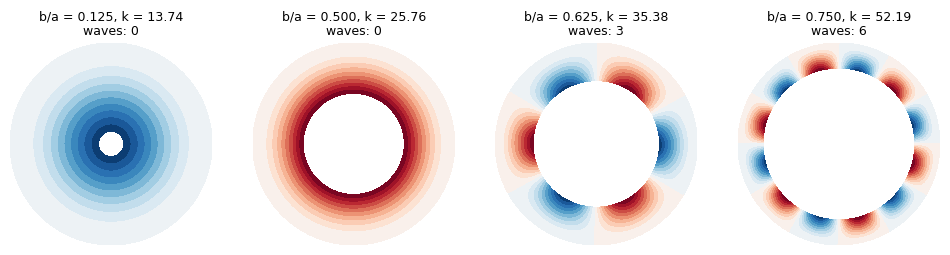

In [6]:
def waves(md, mode):
    ws = []
    for p in md.panels:
        ys = np.linspace(0, p.b, 400)[:, None]
        xs = np.full_like(ys, p.a/2)
        ws.append(p.uvw(mode[p.col_start:p.col_end], xs=xs, ys=ys)[1]['w'].ravel())
    w = np.concatenate(ws)
    # half the number of sign changes along the closed circle
    return np.count_nonzero(np.sign(w) != np.sign(np.roll(w, 1)))//2


RES = {}
for nu in NUS:
    for b in B_IN:
        RES[(b, nu)] = buckling(b, M_FIN, N_FIN, nu)
fig, axes = plt.subplots(1, len(B_IN), figsize=(12, 3.3))
for ax, b in zip(axes, B_IN):
    k, md_, mode = RES[(b, NUS[0])]
    wmax = max(np.abs(p.uvw(mode[p.col_start:p.col_end], gridx=30, gridy=60)[1]['w']).max()
               for p in md_.panels)
    for j, p in enumerate(md_.panels):
        xs, ys = np.meshgrid(np.linspace(0, p.a, 30), np.linspace(0, p.b, 120), indexing='ij')
        w = p.uvw(mode[p.col_start:p.col_end], xs=xs, ys=ys)[1]['w']
        th = ys/A_OUT + j*np.pi
        cs = ax.contourf((A_OUT - xs)*np.cos(th), (A_OUT - xs)*np.sin(th), w/wmax,
                         levels=np.linspace(-1, 1, 21), cmap='RdBu_r')
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title('b/a = %.3f, k = %.2f\nwaves: %d' % (b/A_OUT, k, waves(md_, mode)), fontsize=9)
plt.show()

## 5. Comparison with the experiments

[1] reports the experimental values only as points of its Fig. 2, $k$ against $b/a$. They were read
from the figure (centres of the markers in a 600 dpi image of the PDF, the axis calibrated on the
labels of $k$); the reading is accurate to about $\pm 0.3$ in $k$. For $b = 0$ the reference is
Bryan's clamped circular plate, $k = j_{1,1}^2$, $j_{1,1}$ the first zero of $J_1$ ([1], Fig. 1;
[2], Eq. (32)), which does not depend on $\nu$; the solid plate is not an annular sector.

  b/a  specimen  k experiment [1]  panels nu=0.30  panels nu=0.33  diff (%) nu=0.30  diff (%) nu=0.33
-----  --------  ----------------  --------------  --------------  ----------------  ----------------
0.000         1             14.55           14.68           14.68              +0.9              +0.9
0.000         2             12.95           14.68           14.68             +13.4             +13.4
0.125         1             16.20           13.74           13.62             -15.2             -16.0
0.125         2             14.45           13.74           13.62              -4.9              -5.8
0.500         1             27.87           25.76           25.42              -7.6              -8.8
0.500         2             26.32           25.76           25.42              -2.1              -3.4
0.625         1             41.71           35.38           34.56             -15.2             -17.1
0.625         2             40.16           35.38           34.56             -11.

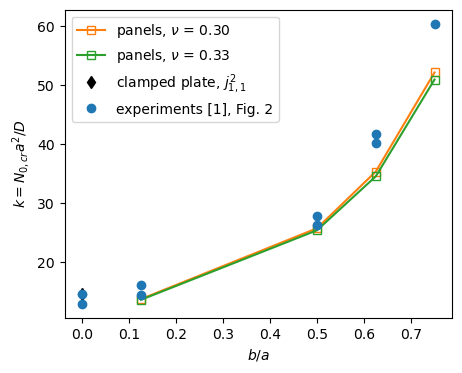

In [7]:
# [1] Fig. 2, read from the figure; two specimens per ratio except b/a = 0.75
K_EXP = {0.: (14.55, 12.95), 0.5: (16.20, 14.45), 2.: (27.87, 26.32),
         2.5: (41.71, 40.16), 3.: (60.46,)}
k_bryan = jn_zeros(1, 1)[0]**2
rows = []
for b, exps in K_EXP.items():
    for i, k_e in enumerate(exps):
        if b == 0:
            th = [k_bryan, k_bryan]
        else:
            th = [abs(RES[(b, nu)][0]) for nu in NUS]
        rows.append(['%.3f' % (b/A_OUT), i + 1, '%.2f' % k_e]
                    + ['%.2f' % t for t in th]
                    + ['%+.1f' % rel(t, k_e) for t in th])
print_table(rows, ['b/a', 'specimen', 'k experiment [1]', 'panels nu=0.30',
                   'panels nu=0.33', 'diff (%) nu=0.30', 'diff (%) nu=0.33'])

fig, ax = plt.subplots(figsize=(5, 4))
for j, nu in enumerate(NUS):
    ax.plot([b/A_OUT for b in B_IN], [abs(RES[(b, nu)][0]) for b in B_IN], 's-',
            color='C%d' % (j + 1), mfc='none', label=r'panels, $\nu$ = %.2f' % nu)
ax.plot([0], [k_bryan], 'kd', label='clamped plate, $j_{1,1}^2$')
for b, exps in K_EXP.items():
    ax.plot([b/A_OUT]*len(exps), exps, 'o', color='C0',
            label='experiments [1], Fig. 2' if b == 0 else None)
ax.set_xlabel('$b/a$')
ax.set_ylabel('$k = N_{0,cr} a^2/D$')
ax.legend()
plt.show()

## 6. Discussion

**Pre-buckling state.** The linear static case reproduces Lamé's solution to all printed digits.

**Convergence.** From $m = 12$, $n = 16$ on, $k$ changes by less than 0.02 %; the finest mesh,
$m = 16$, $n = 20$, is used.

**Modes.** panels finds the axisymmetric mode for $b/a = 0.125$ and $0.5$, as [1] (theory and
tests), three waves for $b/a = 0.625$ and six for $b/a = 0.75$, where [1], Fig. 2, gives two and five
waves. The curves of [1] for $n \ge 2$ come from a one-term Rayleigh-Ritz solution with $w = w_0 (1 -
r^2/a^2)^2 \cos n\theta$ ([1], Eq. (27)), which overestimates the loads (for $b = 0$ it gives $k
\approx 16$ instead of Bryan's 14.68) and can change the order of the curves of neighbouring $n$,
which lie close together for large $b/a$ ([1], p. 1707). The wave numbers observed in the tests of
series B also depend on the imperfections, as [1] remarks.

**Load.** A small hole lowers the load below that of the solid plate (13.7 against 14.7 for $b/a =
0.125$), the circumferential compression doubling at the free edge of the hole; [1], Fig. 2, shows
no such dip because of the one-term approximation. For $b/a \ge 0.5$ the load grows quickly with the
hole, the plate approaching a long strip clamped on one edge and free on the other.

**Experiments.** The tests lie above the computed loads by 2 % to 17 % (except the two solid
plates, 1 % and 12 % below Bryan's value), with $\nu = 0.30$; $\nu = 0.33$ lowers the computed
loads by 1 % to 2 % and increases these differences. [1] explains the higher experimental loads by
slipping between the aluminium plate and the steel rings, which reduces the radial force actually
transmitted at a given temperature, and the temperature in the plate was not uniform (series B); the
experiments therefore support the computed trend of the load and the change of mode with $b/a$
rather than its values.

## References

1. Majumdar, S., "Buckling of a thin annular plate under uniform compression", AIAA Journal,
   Vol. 9, No. 9, 1971, pp. 1701-1707, Eqs. (2) and (8), Table 1, Figs. 1 and 2.
   https://doi.org/10.2514/3.6419
2. Yamaki, N., "Buckling of a thin annular plate under uniform compression", Journal of Applied
   Mechanics, Vol. 25, 1958, pp. 267-273. https://doi.org/10.1115/1.4011755
3. Castro, S. G. P., and Donadon, M. V., "Assembly of semi-analytical models to address linear
   buckling and vibration of stiffened composite panels with debonding defect", Composite
   Structures, Vol. 160, 2017, pp. 232-247. https://doi.org/10.1016/j.compstruct.2016.10.026

In [8]:
print('total run time: %.1f min' % ((time.time() - T_START)/60))

total run time: 4.7 min
